<a href="https://colab.research.google.com/github/Lucasponc3/ProcesamientoDelHabla/blob/main/PONCE_LUCAS_PH_TP1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP1 PROCESAMIENTO DEL HABLA: webscrapping

**Crea una copia de este notebook en tu google colab**

**Renombra el notebook con el siguiente formato APELLIDO_NOMBRE_PH_TP1.ipynb**

**Alumno: Lucas Ponce**


* Resolver las consignas comentando el código fuente, indicando desde dónde fue extraido o generado.

* Explicar y justificar cada paso realizado usando los bloques de texto.

* Publique enlace público a su notebook en google colab y también enlace a su repositorio github de la materia.

## Presentación del trabajo

**Tema:** análisis del discurso de graduación de Bruno Bianchi.

**Fuente:** [Universidad ORT Uruguay](https://www.ort.edu.uy/44412/32). La página presenta las palabras de un graduado de Ingeniería en Sistemas en una ceremonia de **agosto de 2012**.

**Delimitación:** se analiza la intervención desde el saludo hasta el agradecimiento final. Se excluyen el título, la presentación institucional, los menús y el pie del sitio. Se conservan los agradecimientos y la anécdota que forman parte de la intervención. No se agrega texto de otras fuentes.

**Justificación personal:** elegí este discurso por su relación con el aprendizaje, la formación profesional y la superación personal. Me interesa observar cómo un texto de este tipo puede representarse mediante frecuencias y matrices. Antes de entregar, adaptar esta justificación a mis propios motivos.

**Procedencia del desarrollo:** consignas y anexo proporcionados por la cátedra y basados en las referencias técnicas del final. El alumno debe ejecutar y comprender el procedimiento.

**Verificación de esta versión:** se consultó la página con el navegador. El entorno de preparación no pudo resolver el dominio mediante Python. Se probaron por separado la extracción sobre HTML de prueba y el procesamiento del texto consultado en el navegador; eso **no equivale a validar la descarga ni el HTML real**. El notebook se entrega sin salidas precargadas; las cantidades de la entrega deben obtenerse al ejecutarlo.

**Enlace público de Colab:** https://colab.research.google.com/drive/1Qbj6M2kLQHzV_WJh3ZlZ8SROIJLgC0jg?usp=sharing

**Repositorio de GitHub de la materia:** COMPLETAR.


## EJERCICIO CONSIGNA

* Cree una nube de palabras de un texto en español.

* Dicho texto puede ser descargado de Internet (webscrapping) o extraído del dataset de alguna librería.

* Puede usar cualquier libreria o herramienta para obtener el texto de su interés.

* En este notebook explica el paso a paso del proceso.

## 1- Webscrapping

Extrae un texto de Internet de una sóla página web usando alguna de las técnicas de webscrapping vistas en clase. Busca el discurso de alguna persona quien te inspire o haya dado una charla motivadora.

No puedes repetir ni usar ni el mismo texto ni la misma web que otra persona quien ya entregó en el foro.

Abajo añade los bloques de código y texto necesarios. Explica paso a paso como descargaste el texto de tu interés.

### 1.1 Preparación del entorno

`requests` solicita la página; Beautiful Soup permite leer su HTML . Para las stop words y las oraciones se usa **spaCy en español**, con un segmentador basado en reglas. WordCloud genera la nube y scikit-learn construye las matrices .

Esta instalación solo agrega las bibliotecas. No descarga el discurso. La biblioteca escrita como «worldcloud» en la consigna se llama **`wordcloud`**. Ejecutar las celdas en orden; Python 3.10 o posterior.

In [1]:
# Código.
%pip install -q requests beautifulsoup4 "spacy>=3.8,<4" wordcloud scikit-learn pandas matplotlib

In [2]:
# Referencias.
import re
import json
import hashlib
import unicodedata
from collections import Counter
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import requests
from bs4 import BeautifulSoup
import spacy
from spacy.lang.es.stop_words import STOP_WORDS
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from IPython.display import display, Markdown

# La configuración y las stop words están incluidas en spaCy.
nlp = spacy.blank("es")
nlp.add_pipe("sentencizer")
stopwords_es = {unicodedata.normalize("NFC", palabra).lower() for palabra in STOP_WORDS}

CARPETA_SALIDA = Path("resultados_tp1_bruno_bianchi")
CARPETA_SALIDA.mkdir(exist_ok=True)
print("Entorno preparado. Idioma:", nlp.lang)

Entorno preparado. Idioma: es


### 1.2 Descarga de la página

Se solicita **una sola página de contenido**. `raise_for_status()` permite detectar errores HTTP; `timeout=30` limita las esperas por inactividad de la conexión, no el tiempo total de ejecución. El código comprueba también que la respuesta sea HTML.

El HTML queda en memoria. Se registra la URL efectiva, la fecha y su huella SHA-256 para documentar la ejecución. No se publica una copia del discurso completo.

**Uso responsable:** revisar las condiciones del sitio y su [robots.txt](https://www.ort.edu.uy/robots.txt) antes de ejecutar.

In [3]:
# Fuente.
URL = "https://www.ort.edu.uy/44412/32"

try:
    respuesta = requests.get(
        URL,
        headers={"User-Agent": "TP1-ProcesamientoHabla/1.0 (uso educativo)"},
        timeout=30,
    )
    respuesta.raise_for_status()
except requests.RequestException as error:
    raise RuntimeError(
        "No se pudo descargar la página de ORT. Revisá la conexión y el error original. "
        "Si el sitio restringe el acceso, no intentes eludir esa restricción."
    ) from error

if "html" not in respuesta.headers.get("Content-Type", "").lower():
    raise ValueError("La respuesta no contiene HTML. No se continuará el análisis.")

# Se pasan los bytes a Beautiful Soup para respetar la codificación del HTML.
html_descargado = respuesta.content
fecha_descarga_utc = datetime.now(timezone.utc).isoformat()
url_efectiva = respuesta.url
huella_html = hashlib.sha256(html_descargado).hexdigest()

print("Estado HTTP:", respuesta.status_code)
print("URL efectiva:", url_efectiva)
print("Descarga (UTC):", fecha_descarga_utc)
print("Bytes recibidos:", len(html_descargado))

Estado HTTP: 200
URL efectiva: https://www.ort.edu.uy/44412/32
Descarga (UTC): 2026-09-21T22:58:58.473635+00:00
Bytes recibidos: 25843


### 1.3 Extracción exclusiva del discurso

Se eliminan scripts y elementos auxiliares, se obtiene el texto del HTML y se unifican los espacios. Después se recorta entre el inicio y el cierre identificados en la fuente. Esta estrategia **no depende de adivinar el nombre de una clase CSS**.

El resultado conserva palabras y puntuación, pero no la distribución visual en párrafos: la unidad de análisis será la oración. Se verifica que los límites aparezcan una sola vez y que existan dos marcadores internos. Son controles de estructura, **no una garantía de integridad**: comparar el resultado con la página visible sigue siendo necesario.

In [4]:
# Extracción.
def extraer_discurso(html: bytes) -> str:
    """Recorta el discurso; informa errores en vez de aceptar una página inesperada."""
    sopa = BeautifulSoup(html, "html.parser")
    for etiqueta in sopa.select("script, style, noscript, template, iframe, nav, footer, aside"):
        etiqueta.decompose()

    cuerpo = sopa.body or sopa
    texto_pagina = re.sub(r"\s+", " ", cuerpo.get_text(" ", strip=True)).strip()
    texto_pagina = unicodedata.normalize("NFC", texto_pagina)

    # Fragmentos breves de la fuente para delimitar el contenido, no texto agregado.
    inicio = "Autoridades de la Universidad ORT Uruguay"
    cierre = "Muchas gracias por vuestra atención."
    inicios = list(re.finditer(re.escape(inicio), texto_pagina, flags=re.IGNORECASE))
    cierres = list(re.finditer(re.escape(cierre), texto_pagina, flags=re.IGNORECASE))

    if len(inicios) != 1 or len(cierres) != 1:
        raise ValueError(
            "No se detectaron límites únicos del discurso. "
            f"Inicios encontrados: {len(inicios)}; cierres: {len(cierres)}. "
            "Revisá el HTML: puede estar incompleto o haber cambiado."
        )
    if inicios[0].start() >= cierres[0].start():
        raise ValueError("El cierre aparece antes del inicio. Revisá la extracción.")

    texto = texto_pagina[inicios[0].start():cierres[0].end()]
    marcadores_internos = ("mejorar continuamente", "artes marciales")
    if len(texto) < 1000 or not all(m in texto.lower() for m in marcadores_internos):
        raise ValueError("El contenido no supera los controles mínimos. Revisá la página.")
    return texto


texto_original = extraer_discurso(html_descargado)
print("Controles de inicio, cierre y marcadores internos: correctos.")
print("Caracteres extraídos:", len(texto_original))
print("El discurso está disponible en la variable texto_original para revisión local.")

Controles de inicio, cierre y marcadores internos: correctos.
Caracteres extraídos: 2339
El discurso está disponible en la variable texto_original para revisión local.


**Control del contenido.** Revisar localmente `texto_original` y compararlo con la página: comienzo, un tramo intermedio y final. No borrar automáticamente repeticiones genuinas, porque afectan las frecuencias. El notebook no imprime el discurso completo para no incorporarlo a la publicación del trabajo.

A partir de aquí se usa **el mismo texto en español** para todas las consignas. No se traduce, se amplía ni se sustituye por contenido de otra página.

## 2- Preprocesamiento

### 2.1 Muestra las stop words que tenga tu texto.

Se usa la lista de stop words en español de spaCy [5]. Se cuentan **solamente las que aparecen en el discurso**, en lugar de mostrar toda la lista como si estuviera presente.

Para contar palabras se pasa a minúsculas y se conservan secuencias alfabéticas del español, incluidas tildes, `ñ` y `ü`. `texto_original` permanece sin esta limpieza para poder segmentarlo después. Las palabras que se omiten dependen de la lista elegida; «no» también está en ella. Esta elección sirve al ejercicio de frecuencias, no a un análisis de negaciones.

In [5]:
# Implementación.
def extraer_palabras(texto: str) -> list[str]:
    """Devuelve tokens alfabéticos en minúsculas, conservando caracteres del español."""
    texto = unicodedata.normalize("NFC", texto).lower()
    texto = re.sub(r"https?://\S+|www\.\S+|\S+@\S+", " ", texto)
    return re.findall(r"\b[a-záéíóúüñ]+\b", texto)


palabras_originales = extraer_palabras(texto_original)
frecuencias_stopwords = Counter(
    palabra for palabra in palabras_originales if palabra in stopwords_es
)
tabla_stopwords = pd.DataFrame(
    frecuencias_stopwords.most_common(), columns=["stop_word", "frecuencia"]
)

print("Stop words distintas presentes:", len(frecuencias_stopwords))
print("Total de apariciones de stop words:", sum(frecuencias_stopwords.values()))
print(tabla_stopwords.to_string(index=False))

Stop words distintas presentes: 76
Total de apariciones de stop words: 211
stop_word  frecuencia
      que          15
       la          14
        y          13
       de          12
      por          12
       en          11
        a          10
       su           8
       un           7
      una           5
      con           5
       no           5
     para           4
       el           4
      nos           4
      hoy           3
      sus           3
   muchas           3
       es           2
  ustedes           2
     hace           2
  algunos           2
    desde           2
 nuestros           2
  posible           2
      los           2
   muchos           2
     esto           2
     sólo           2
     sino           2
  también           2
       al           2
  nuestra           2
    todos           1
   buenas           1
       mí           1
    poder           1
      mis           1
    nueva           1
       ya           1
   cuando           1
 

### 2.2 Quita las stop-words, caracteres extraños del texto. Utiliza el texto restante para crear una nube de palabras. Usa la biblioteca worldcloud de python.

Se eliminan stop words, números, signos y símbolos, además de tokens de una sola letra. **No se eliminan las tildes ni la ñ.** No se hace lematización: singular y plural, o distintas conjugaciones, pueden quedar como términos diferentes.

La función de limpieza será la misma para la nube y las oraciones. La nube se construye a partir de las frecuencias ya calculadas, sin aplicar una segunda tokenización [6]. El tamaño tipográfico permite explorar el resultado; para cantidades exactas se consulta la tabla. Una palabra frecuente no es necesariamente la idea más importante del discurso.

In [6]:
# Una misma función de limpieza para todo el trabajo.
def limpiar_texto(texto: str) -> str:
    palabras = extraer_palabras(texto)
    return " ".join(
        palabra for palabra in palabras
        if palabra not in stopwords_es and len(palabra) > 1
    )


texto_limpio = limpiar_texto(texto_original)
palabras_limpias = texto_limpio.split()
frecuencias = Counter(palabras_limpias)
if not frecuencias:
    raise ValueError("No quedaron palabras después de limpiar. Revisá el texto extraído.")

tabla_frecuencias = pd.DataFrame(
    frecuencias.most_common(), columns=["palabra", "frecuencia"]
)
print("Tokens alfabéticos antes del filtrado:", len(palabras_originales))
print("Tokens después del filtrado:", len(palabras_limpias))
print("Palabras más frecuentes:")
display(tabla_frecuencias.head(12))

Tokens alfabéticos antes del filtrado: 360
Tokens después del filtrado: 149
Palabras más frecuentes:


,palabra,frecuencia
0,universidad,3
1,vida,3
2,profesional,3
3,gracias,3
4,persona,3
5,celebramos,2
6,años,2
7,experiencia,2
8,aprender,2
9,frente,2


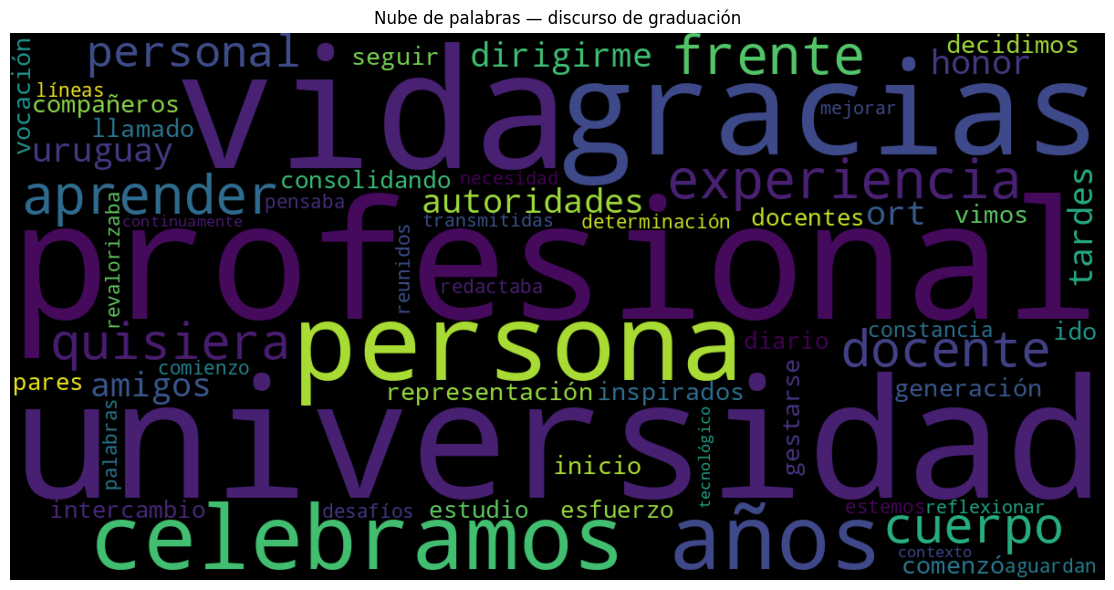

Imagen guardada en: resultados_tp1_bruno_bianchi/nube_palabras_bruno_bianchi.png


In [7]:
# API de WordCloud. Colores predeterminados de la biblioteca.
nube = WordCloud(
    width=1200,
    height=600,
    max_words=60,
    random_state=42,
).generate_from_frequencies(frecuencias)

plt.figure(figsize=(12, 6))
plt.imshow(nube, interpolation="bilinear")
plt.axis("off")
plt.title("Nube de palabras — discurso de graduación")
plt.tight_layout()
plt.show()

ruta_nube = CARPETA_SALIDA / "nube_palabras_bruno_bianchi.png"
nube.to_file(str(ruta_nube))
print("Imagen guardada en:", ruta_nube)

### 2.3 Usando el texto que conseguiste en el punto 1).

#### 2.3.1 Limpia y preprocesa el texto, descomponelo en oraciones, arma una matriz documento-vocabulario.

**Cada oración será un documento.** Primero se divide `texto_original`, con su puntuación, y después se limpia cada oración. No se intenta reconstruir oraciones a partir de `texto_limpio`.

El componente `sentencizer` de spaCy usa reglas para establecer límites; no interpreta el significado y puede equivocarse ante abreviaturas o citas [4]. Se conserva la correspondencia con el texto original y se informa cuántas oraciones quedan vacías después del filtrado. No se eliminan oraciones por el solo hecho de repetirse.

In [8]:
# Segmentación basada en reglas; no requiere un modelo entrenado.
oraciones_originales = [oracion.text.strip() for oracion in nlp(texto_original).sents]
registros = []
for numero, oracion in enumerate(oraciones_originales, start=1):
    oracion_limpia = limpiar_texto(oracion)
    if oracion_limpia:
        registros.append({
            "documento": f"oracion_{numero:02d}",
            "texto_original": oracion,
            "texto_limpio": oracion_limpia,
        })

if len(registros) < 2:
    raise ValueError("Se necesitan al menos dos oraciones útiles para este análisis.")

df_oraciones = pd.DataFrame(registros).set_index("documento")
documentos = df_oraciones["texto_limpio"].tolist()
print("Oraciones detectadas:", len(oraciones_originales))
print("Oraciones conservadas:", len(documentos))
print("Oraciones vacías descartadas:", len(oraciones_originales) - len(documentos))

# Control cuantitativo sin publicar el texto de todas las oraciones.
control_oraciones = pd.DataFrame({
    "caracteres_originales": df_oraciones["texto_original"].str.len(),
    "tokens_limpios": df_oraciones["texto_limpio"].str.split().str.len(),
})
display(control_oraciones.head(6))
# Revisar df_oraciones de forma local para comprobar los límites de cada oración.

Oraciones detectadas: 15
Oraciones conservadas: 15
Oraciones vacías descartadas: 0


,caracteres_originales,tokens_limpios
documento,,
oracion_01,71,6
oracion_02,96,5
oracion_03,344,25
oracion_04,109,6
oracion_05,202,12
oracion_06,358,23


**Matriz documento-vocabulario.** `CountVectorizer` crea una matriz de conteos: filas = oraciones; columnas = palabras distintas; celdas = apariciones de una palabra en una oración [7]. Cero significa ausencia.

Como la limpieza ya está hecha, se usa `str.split` y se desactiva la tokenización predeterminada. El formato disperso almacena las entradas no nulas; se muestra un recorte para facilitar la lectura. La matriz completa permanece en la variable indicada.

In [9]:
# Representación de bolsa de palabras.
vectorizador = CountVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    lowercase=False,
)
matriz_conteos = vectorizador.fit_transform(documentos)
vocabulario = vectorizador.get_feature_names_out()
matriz_documento_vocabulario = pd.DataFrame.sparse.from_spmatrix(
    matriz_conteos, index=df_oraciones.index, columns=vocabulario
)

columnas_muestra = [palabra for palabra, _ in frecuencias.most_common(10)]
print("Dimensiones (oraciones, palabras distintas):", matriz_conteos.shape)
display(matriz_documento_vocabulario.loc[:, columnas_muestra].head(6))

Dimensiones (oraciones, palabras distintas): (15, 130)


,universidad,vida,profesional,gracias,persona,celebramos,años,experiencia,aprender,frente
documento,,,,,,,,,,
oracion_01,1,0,0,0,0,0,0,0,0,0
oracion_02,0,0,0,0,0,0,0,0,0,0
oracion_03,0,3,3,0,0,1,1,1,0,0
oracion_04,0,0,0,0,0,1,0,0,0,0
oracion_05,1,0,0,0,0,0,0,0,2,0
oracion_06,0,0,0,0,0,0,0,0,0,2


#### 2.3.2 Determina la longitud de tu vocabulario.

La longitud del vocabulario es el número de palabras **distintas**, no el total de apariciones. En el ejemplo inventado `estudio práctica estudio`, hay tres tokens y dos términos distintos.

La cantidad debe coincidir con las columnas de la matriz. Se comprueba también que la suma de cada columna reproduzca exactamente las frecuencias usadas en la nube.

In [10]:
longitud_vocabulario = len(vocabulario)
print("Longitud del vocabulario:", longitud_vocabulario)
print("Total de tokens limpios:", len(palabras_limpias))

assert longitud_vocabulario == matriz_conteos.shape[1]
assert set(vocabulario) == set(frecuencias)
conteos_por_palabra = np.asarray(matriz_conteos.sum(axis=0)).ravel()
assert all(
    int(conteos_por_palabra[i]) == frecuencias[palabra]
    for i, palabra in enumerate(vocabulario)
), "La nube y la matriz no coinciden: revisar la limpieza o la segmentación."
print("Control correcto: nube y matriz usan las mismas palabras y frecuencias.")

Longitud del vocabulario: 130
Total de tokens limpios: 149
Control correcto: nube y matriz usan las mismas palabras y frecuencias.


#### 2.3.3. Aplica TF-IDF a tu matriz documento-vocabulario

Se aplica `TfidfTransformer` **a la matriz de conteos anterior**, sin reconstruir el vocabulario [8].

Con la configuración elegida, TF es el conteo de una palabra en una oración; DF es el número de oraciones que la contienen, no su cantidad de apariciones. Si $N$ es el número de oraciones, el IDF suavizado es:

$$\operatorname{idf}(t)=\ln\left(\frac{1+N}{1+\operatorname{df}(t)}\right)+1$$

Primero se multiplica cada conteo por su IDF. Después, `norm="l2"` divide cada fila por su norma euclídea. **El resultado no es un porcentaje.** Los términos distribuidos entre menos oraciones tienen mayor IDF, aunque el peso final depende también del conteo y la normalización.

La forma de la matriz se conserva: una fila por oración y una columna por palabra. Estas operaciones no proporcionan por sí mismas una interpretación del mensaje.

In [11]:
# Parámetros.
transformador_tfidf = TfidfTransformer(
    norm="l2", use_idf=True, smooth_idf=True, sublinear_tf=False
)
matriz_tfidf = transformador_tfidf.fit_transform(matriz_conteos)
df_tfidf = pd.DataFrame.sparse.from_spmatrix(
    matriz_tfidf, index=df_oraciones.index, columns=vocabulario
)

print("Dimensiones TF-IDF:", matriz_tfidf.shape)
display(df_tfidf.loc[:, columnas_muestra].head(6).sparse.to_dense().round(4))

assert matriz_tfidf.shape == matriz_conteos.shape
normas = np.sqrt(np.asarray(matriz_tfidf.multiply(matriz_tfidf).sum(axis=1)).ravel())
assert np.allclose(normas, 1.0)
print("Control correcto: cada fila no vacía tiene norma L2 igual a 1.")

Dimensiones TF-IDF: (15, 130)


,universidad,vida,profesional,gracias,persona,celebramos,años,experiencia,aprender,frente
documento,,,,,,,,,,
oracion_01,0.3274,0.0000,0.0000,0.0,0.0,0.0000,0.0000,0.0000,0.0000,0.0
oracion_02,0.0000,0.0000,0.0000,0.0,0.0,0.0000,0.0000,0.0000,0.0000,0.0
oracion_03,0.0000,0.4982,0.4982,0.0,0.0,0.1442,0.1442,0.1442,0.0000,0.0
oracion_04,0.0000,0.0000,0.0000,0.0,0.0,0.3620,0.0000,0.0000,0.0000,0.0
oracion_05,0.2101,0.0000,0.0000,0.0,0.0,0.0000,0.0000,0.0000,0.5423,0.0
oracion_06,0.0000,0.0000,0.0000,0.0,0.0,0.0000,0.0000,0.0000,0.0000,0.4


Control correcto: cada fila no vacía tiene norma L2 igual a 1.


**Ejemplo para interpretar una celda.** En la primera oración útil se identifica el término con mayor peso y se reconstruye su TF-IDF. Esto permite relacionar una celda de la matriz con su conteo, su presencia en otras oraciones y el factor de normalización. No es un ranking global de importancia del discurso.

In [12]:
# Verificación numérica.
fila = 0
pesos = matriz_tfidf.getrow(fila).toarray().ravel()
j = int(np.argmax(pesos))
N = matriz_conteos.shape[0]
tf = int(matriz_conteos[fila, j])
df_termino = int((matriz_conteos[:, j] > 0).sum())
idf_manual = np.log((1 + N) / (1 + df_termino)) + 1
fila_ponderada = matriz_conteos.getrow(fila).toarray().ravel() * transformador_tfidf.idf_
norma_fila = np.linalg.norm(fila_ponderada)
peso_manual = tf * idf_manual / norma_fila

print("Documento:", df_oraciones.index[fila])
print("Palabra:", vocabulario[j])
print("TF:", tf, "| DF:", df_termino, "| N:", N)
print("IDF:", round(float(idf_manual), 6))
print("Norma de la fila antes de normalizar:", round(float(norma_fila), 6))
print("TF-IDF calculado:", round(float(peso_manual), 6))
assert np.isclose(peso_manual, matriz_tfidf[fila, j])

Documento: oracion_01
Palabra: amigos
TF: 1 | DF: 1 | N: 15
IDF: 3.079442
Norma de la fila antes de normalizar: 7.287606
TF-IDF calculado: 0.422559


Explica el formato de tu matriz resultante: documentos, vocabulario, tamaño. Brinda tus conclusiones.

En ambas matrices, los **documentos** son las oraciones que conservaron palabras tras la limpieza y el **vocabulario** está formado por los términos distintos que quedaron. El tamaño se expresa como **filas × columnas**.

La primera matriz contiene conteos enteros; la segunda, pesos decimales. Las ausencias siguen siendo ceros. No se conservan el orden de las palabras ni las relaciones gramaticales dentro de cada fila. Las cifras concretas se obtienen a continuación, sin escribir valores supuestos.

In [13]:
resumen = pd.DataFrame({
    "medida": [
        "Caracteres extraídos", "Tokens alfabéticos originales", "Tokens limpios",
        "Oraciones detectadas", "Documentos conservados (filas)",
        "Palabras distintas (columnas)", "Celdas no nulas en conteos",
    ],
    "valor": [
        len(texto_original), len(palabras_originales), len(palabras_limpias),
        len(oraciones_originales), len(documentos), longitud_vocabulario, matriz_conteos.nnz,
    ],
})
display(resumen)
porcentaje_ceros = 100 * (1 - matriz_conteos.nnz / (len(documentos) * longitud_vocabulario))
print(f"Celdas con cero: {porcentaje_ceros:.2f}%")

,medida,valor
0,Caracteres extraídos,2339
1,Tokens alfabéticos originales,360
2,Tokens limpios,149
3,Oraciones detectadas,15
4,Documentos conservados (filas),15
5,Palabras distintas (columnas),130
6,Celdas no nulas en conteos,143


Celdas con cero: 92.67%


# Conclusiones
El procedimiento separa la obtención del contenido, su limpieza y la representación numérica. La extracción acotada evita que los menús y la presentación de la página se mezclen con el discurso.

La nube muestra frecuencias de las palabras conservadas. La matriz de conteos registra sus apariciones por oración, mientras que TF-IDF las pondera según su distribución entre oraciones y normaliza cada fila. Por eso frecuencia alta y peso TF-IDF alto no responden a la misma pregunta.

**Limitaciones:** se trabaja con un único texto breve. Los resultados dependen de la lista de stop words, que también elimina negaciones, y de la segmentación automática. No se unifican plurales ni conjugaciones. Las matrices no preservan toda la estructura del lenguaje, ni permiten generalizar a otros discursos o inferir intenciones del autor. No se corrigen ni se completan las afirmaciones de la fuente.

Al representar el discurso mediante frecuencias se pierde parte de la información original, principalmente el orden de las palabras, el contexto, las relaciones gramaticales y algunos matices como las negaciones. La frecuencia permite saber qué términos aparecen más veces, pero no permite comprender por sí sola el significado completo ni la intención del discurso.

In [14]:
# El párrafo se construye con la ejecución actual, sin cifras precargadas.
terminos_destacados = ", ".join(
    f"{palabra} ({cantidad})" for palabra, cantidad in frecuencias.most_common(5)
)
conclusion_resultados = (
    f"Se detectaron {len(oraciones_originales)} oraciones y se conservaron "
    f"{len(documentos)} después de la limpieza. El texto limpio contiene "
    f"{len(palabras_limpias)} tokens y un vocabulario de {longitud_vocabulario} "
    f"palabras distintas. Las matrices de conteos y TF-IDF tienen "
    f"{len(documentos)} filas y {longitud_vocabulario} columnas. "
    f"Las cinco palabras más frecuentes fueron: {terminos_destacados}. "
    "Estas cifras describen únicamente el texto seleccionado con los criterios aplicados."
)
display(Markdown(conclusion_resultados))

Se detectaron 15 oraciones y se conservaron 15 después de la limpieza. El texto limpio contiene 149 tokens y un vocabulario de 130 palabras distintas. Las matrices de conteos y TF-IDF tienen 15 filas y 130 columnas. Las cinco palabras más frecuentes fueron: universidad (3), vida (3), profesional (3), gracias (3), persona (3). Estas cifras describen únicamente el texto seleccionado con los criterios aplicados.

## Registro de la ejecución

Se guardan la nube y un registro técnico con la fuente, las versiones y las dimensiones. No se exporta el discurso completo ni las oraciones. La huella identifica el contenido procesado; no demuestra que sea completo. Los resultados pueden variar si cambian la página o las bibliotecas.

In [15]:
paquetes = ["requests", "beautifulsoup4", "spacy", "wordcloud", "scikit-learn", "pandas", "matplotlib"]
versiones = {paquete: version(paquete) for paquete in paquetes}
registro = {
    "fuente": URL,
    "url_efectiva": url_efectiva,
    "fecha_descarga_utc": fecha_descarga_utc,
    "sha256_html": huella_html,
    "sha256_texto": hashlib.sha256(texto_original.encode("utf-8")).hexdigest(),
    "idioma": "español; sin traducción",
    "lista_stopwords": "spaCy / español",
    "segmentacion": "spaCy blank(es) + sentencizer; basada en reglas",
    "oraciones_detectadas": len(oraciones_originales),
    "filas": int(matriz_conteos.shape[0]),
    "columnas": int(matriz_conteos.shape[1]),
    "tokens_limpios": len(palabras_limpias),
    "versiones": versiones,
}
ruta_registro = CARPETA_SALIDA / "registro_ejecucion.json"
ruta_registro.write_text(json.dumps(registro, ensure_ascii=False, indent=2), encoding="utf-8")
display(pd.DataFrame(list(versiones.items()), columns=["biblioteca", "version"]))
print("Registro guardado en:", ruta_registro)

,biblioteca,version
0,requests,2.32.4
1,beautifulsoup4,4.13.5
2,spacy,3.8.16
3,wordcloud,1.9.6
4,scikit-learn,1.6.1
5,pandas,2.2.3
6,matplotlib,3.10.0


Registro guardado en: resultados_tp1_bruno_bianchi/registro_ejecucion.json


## Referencias

[1] Universidad ORT Uruguay. [Discurso de Bruno Bianchi, ceremonia de agosto de 2012](https://www.ort.edu.uy/44412/32). Única fuente del texto analizado.

[2] Requests. [Quickstart: solicitudes, contenido, errores y timeout](https://requests.readthedocs.io/en/latest/user/quickstart/).

[3] Beautiful Soup. [Documentación: análisis del HTML y extracción de texto](https://www.crummy.com/software/BeautifulSoup/bs4/doc/).

[4] spaCy. [Configuración de idiomas sin modelo entrenado](https://spacy.io/usage/models) y [Sentencizer](https://spacy.io/api/sentencizer).

[5] spaCy. [Lista de stop words en español, repositorio oficial](https://github.com/explosion/spaCy/blob/master/spacy/lang/es/stop_words.py).

[6] WordCloud. [WordCloud y generate_from_frequencies](https://amueller.github.io/word_cloud/generated/wordcloud.WordCloud.html).

[7] scikit-learn. [CountVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html).

[8] scikit-learn. [TfidfTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfTransformer.html).



## Antes de entregar

Ejecutar todas las celdas en orden, comprobar la extracción y revisar las conclusiones. Completar los enlaces de Colab y GitHub en la presentación; verificar que el discurso y el sitio no estén repetidos en el foro. Guardar con el nombre **PONCE_LUCAS_PH_TP1.ipynb**.

Para comprobar que entendí el trabajo: explicar qué representa una fila, por qué el vocabulario no es igual a la cantidad total de palabras y por qué TF-IDF no es un porcentaje.

# Anexo, código de ejemplo del uso de wordcloud

Instalar e importar la librería

**Anexo de referencia de la cátedra.** Se conserva como bloques de texto, sin salidas antiguas. No forma parte de la ejecución de la solución ni sobrescribe sus variables. La solución usa la lista de stop words indicada en [5]; este anexo muestra otra lista de ejemplo.

```python
# instalar wordcloud
!pip install wordcloud
```

```python
# Importar librerías
from wordcloud import WordCloud
import matplotlib.pyplot as plt
```

```python
# Texto de ejemplo
text = "Este es un texto de ejemplo para crear una nube de palabras usando word cloud. Puedes reemplazar este texto utilizando tu propio texto."

# Crear un objeto WordCloud
wordcloud = WordCloud(width=800, height=400, background_color="white").generate(text)
```

Mostramos la imagen generada

```python
# mostramos la imagen generada
plt.figure(figsize=(8, 8), facecolor=None)
plt.imshow(wordcloud)
plt.axis("off")
plt.tight_layout(pad=0)
plt.show()
```

Modificamos el ejemplo anterior agregando palabras en español que no queremos que considere para crear la nube de palabras. Estas son las stop_words

```python
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

# Texto de ejemplo
text = "Este es un texto de ejemplo para crear una nube de palabras usando word cloud. Puedes reemplazar este texto utilizando tu propio texto."

# Definir stopwords en español
stopwords_es = set(STOPWORDS)
stopwords_es.update(["con", "que", "los", "para", "un", "una", "el", "la", "en", "y", "o", "de", "a", "se", "es", "al", "como", "por", "no", "su", "más", "pero", "si", "este", "esta", "eso", "esa", "todo", "todos", "todas", "cada", "cual", "cualquier", "algo", "alguna", "algún", "ningún", "ninguna", "ninguno", "otro", "otros", "otras", "sobre", "entre", "durante", "desde", "hasta", "también", "así", "mismo", "misma", "mismo", "misma", "tan", "tanto", "tanta", "muy", "poco", "poca", "poco", "nada", "solo", "sola", "solo", "sola", "siempre", "nunca", "jamás", "casi", "aproximadamente", "cerca", "lejos", "antes", "después", "ahora", "hoy", "ayer", "mañana", "luego", "mientras", "mientras tanto", "después de", "antes de", "durante", "sin", "aunque", "a pesar de", "debido a", "gracias a", "por qué", "cómo", "dónde", "cuándo", "quién", "qué", "cuál"])

# Crear un objeto WordCloud con stopwords en español
wordcloud = WordCloud(width=800, height=400, background_color="white", stopwords=stopwords_es).generate(text)

# Mostramos la imagen generada
plt.figure(figsize=(8, 8), facecolor=None)
plt.imshow(wordcloud)
plt.axis("off")
plt.tight_layout(pad=0)
plt.show()
```

```python

```